# Analysis
### Imports 
#### Run cell to load neccessary packages

In [28]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

### Connect to database

In [15]:
conn = sqlite3.connect("./data/omny.db")

## Questions
### Question 1
What are the top 5 busiest hours and days?
This is interesting to see how the intuition of how busy the subway is aligns with reality. It makes sense that rush hour in the morning and everning towards the middle of the week where hybrid workers are more likely come to the office would be the peak.

In [16]:
query = """
SELECT day_of_week, hour_of_day, avg(est_avg_ridership) as avg_ridership
FROM RIDERSHIP
group by day_of_week, hour_of_day
order by avg_ridership desc
limit 5;
"""

df = pd.read_sql_query(query, conn)

df

,day_of_week,hour_of_day,avg_ridership
0,Tuesday,8,13.527166
1,Wednesday,8,13.451366
2,Tuesday,17,13.191865
3,Wednesday,17,12.873514
4,Thursday,8,12.304231


### Question 2
What are the 10 busiest routes? I ordered by the sum in order to account for outliars. It is interesting to see how the routes appear symetric it would be interesting to see if that is an effect of how the MTA calculates the average ridership, is correlated in the data, or the mechanism behind it. I think that a station pair would have similar needs as people flow through the system so we see the city self sorting to where they need to go.

In [24]:
query = """
SELECT origin.station_name as origin_station, destination.station_name as destination_station, sum(est_avg_ridership) as avg_ridership
FROM RIDERSHIP
join STATION origin on RIDERSHIP.origin_station_id = origin.station_id
join STATION destination on RIDERSHIP.destination_station_id = destination.station_id
group by RIDERSHIP.origin_station_id, RIDERSHIP.destination_station_id
order by avg_ridership desc
limit 10;
"""

df = pd.read_sql_query(query, conn)

df

,origin_station,destination_station,avg_ridership
0,"49 St (N,R,W)","23 St (R,W)",38481.4841
1,"23 St (R,W)","49 St (N,R,W)",34898.8934
2,"49 St (N,R,W)","8 St-NYU (R,W)",30651.5688
3,"8 St-NYU (R,W)","49 St (N,R,W)",29075.7948
4,"57 St-7 Av (N,Q,R,W)","23 St (R,W)",29045.1035
5,"23 St (R,W)","57 St-7 Av (N,Q,R,W)",28952.5928
6,"49 St (N,R,W)","Astoria-Ditmars Blvd (N,W)",27700.2917
7,"57 St-7 Av (N,Q,R,W)","Astoria-Ditmars Blvd (N,W)",26528.3521
8,"Astoria-Ditmars Blvd (N,W)","49 St (N,R,W)",25986.3146
9,"49 St (N,R,W)","30 Av (N,W)",25474.8371


## Questions
### Question 3
How busy is each hour at their busiest. This continues to demonstrate the rsuh hour peak while also showing a surge in the later evening as nightlife/events settle down at 9 before the city quiets down for the evening.

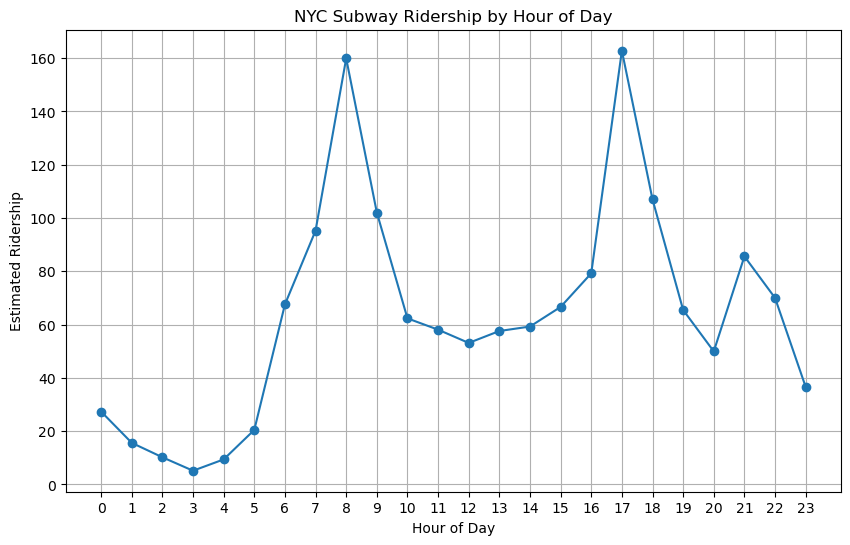

In [31]:
query = """
SELECT hour_of_day, max(est_avg_ridership) as max_ridership
FROM RIDERSHIP
group by hour_of_day
order by hour_of_day;
"""

df = pd.read_sql_query(query, conn)

df

plt.figure(figsize=(10, 6))
plt.plot(
    df["hour_of_day"],
    df["max_ridership"],
    marker="o"
)

plt.title("NYC Subway Ridership by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Estimated Ridership")
plt.grid(True)
plt.xticks(range(24))
plt.show()